# 04 — Apprentissage supervisé : prévision de la température régionale du mois suivant

> Exécutez les cellules dans l'ordre. Les résultats sont régénérés à partir des données brutes ; les notebooks ne dépendent pas des anciens fichiers de sortie.

## Question de modélisation
Pouvons-nous construire un exemple éducatif pour prédire la **moyenne de température de l'Algérie pour le mois cible** à partir des informations des mois précédents ? L'unité d'observation est un mois régional unique, et la cible est `t2m` en degrés Celsius. Le registre contient seulement 141 mois, donc les résultats doivent être interprétés avec prudence et ne constituent pas une prévision climatique opérationnelle.

In [ ]:
from pathlib import Path
import sys

# Locate the project whether Jupyter was started in the project root or notebooks/.
_here = Path.cwd().resolve()
_candidates = [_here, *_here.parents]
PROJECT_ROOT = next((p for p in _candidates if (p / "data" / "raw" / "era5_algeria_raw.nc").exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Start Jupyter from the project root or notebooks/ folder.")
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from climate_utils import (
    load_masked_dataset, make_algeria_mask, load_boundary,
    regional_time_series, to_analysis_units, area_weighted_mean,
)

plt.style.use("seaborn-v0_8-whitegrid")
RANDOM_STATE = 42
print("Project root:", PROJECT_ROOT)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

raw_ds, mask, geometry = load_masked_dataset(PROJECT_ROOT)
regional = to_analysis_units(regional_time_series(raw_ds, mask))
regional = regional.sort_index()
print("Nombre de mois:", len(regional), "Période:", regional.index.min(), "à", regional.index.max())

Project root: /home/ubuntu/work/climate_project/Climate_Data_Mining12345/Climate_Data_Mining


عدد الأشهر: 141 الفترة: 2015-01-01 00:00:00 إلى 2026-09-01 00:00:00


## Création de caractéristiques temporelles sans utiliser le futur
Pour chaque mois cible, nous utilisons les décalages des mois 1, 2, 3 et 12, et une moyenne mobile calculée uniquement à partir du passé. Le numéro du mois cible est connu à l'avance et est converti en une représentation sinusoïdale/cosinus pour la saisonnalité. Nous n'utilisons pas la température du mois cible ni aucune valeur mesurée après.

In [ ]:
features = pd.DataFrame(index=regional.index)
source_variables = [c for c in ["t2m", "d2m", "tp", "wind10_speed"] if c in regional.columns]
for variable in source_variables:
    for lag in [1, 2, 3, 12]:
        features[f"{variable}_lag{lag}"] = regional[variable].shift(lag)
features["t2m_previous_3month_mean"] = regional["t2m"].shift(1).rolling(3, min_periods=3).mean()
month = features.index.month
features["target_month_sin"] = np.sin(2 * np.pi * month / 12)
features["target_month_cos"] = np.cos(2 * np.pi * month / 12)
target = regional["t2m"].rename("target_t2m_c")
model_data = features.join(target).dropna()
X = model_data.drop(columns="target_t2m_c")
y = model_data["target_t2m_c"]
print("Nombre de caractéristiques:", X.shape[1], "; nombre d'exemples de prévision après décalages:", len(X))
display(model_data.head())

عدد الخصائص: 19 ؛ عدد أمثلة التنبؤ بعد التأخيرات: 129


,t2m_lag1,t2m_lag2,t2m_lag3,t2m_lag12,d2m_lag1,d2m_lag2,d2m_lag3,d2m_lag12,tp_lag1,tp_lag2,tp_lag3,tp_lag12,wind10_speed_lag1,wind10_speed_lag2,wind10_speed_lag3,wind10_speed_lag12,t2m_previous_3month_mean,target_month_sin,target_month_cos,target_t2m_c
valid_time,,,,,,,,,,,,,,,,,,,,
2016-01-01,12.185469,17.378512,25.192381,10.701772,0.198997,3.154381,7.468230,-4.364057,0.009015,0.131082,0.425968,0.208876,3.052967,2.135009,0.504952,1.223312,18.252121,0.500000,8.660254e-01,13.547751
2016-02-01,13.547751,12.185469,17.378512,13.689666,-2.336546,0.198997,3.154381,-2.733047,0.095208,0.009015,0.131082,0.523205,1.322416,3.052967,2.135009,1.050118,14.370577,0.866025,5.000000e-01,15.639638
2016-03-01,15.639638,13.547751,12.185469,16.779881,-3.799980,-2.336546,0.198997,-2.354171,0.150887,0.095208,0.009015,0.362976,1.007911,1.322416,3.052967,0.968033,13.790953,1.000000,6.123234e-17,17.423481
2016-04-01,17.423481,15.639638,13.547751,24.797454,-5.490354,-3.799980,-2.336546,-4.934355,0.215764,0.150887,0.095208,0.033328,0.767701,1.007911,1.322416,1.019113,15.536957,0.866025,-5.000000e-01,25.685624
2016-05-01,25.685624,17.423481,15.639638,28.971948,-0.818176,-5.490354,-3.799980,-1.789006,0.206815,0.215764,0.150887,0.083865,0.948271,0.767701,1.007911,1.109034,19.582915,0.500000,-8.660254e-01,28.820505


## Division temporelle et test final
Nous n'utilisons pas `train_test_split` aléatoire : il peut mélanger des mois proches et gonfler l'évaluation. Nous réservons la partie la plus récente pour le test, et plaçons un écart d'un mois illustratif entre l'entraînement et le test. Dans une application opérationnelle réelle, l'écart est déterminé selon l'horizon de prévision et la disponibilité des mesures au moment de la prévision.

In [ ]:
split_at = int(len(model_data) * 0.80)
gap = 1
train_end = split_at - gap
X_train, y_train = X.iloc[:train_end], y.iloc[:train_end]
X_test, y_test = X.iloc[split_at:], y.iloc[split_at:]
if len(X_test) < 12:
    print("Attention : période de test relativement courte ; interprétez les métriques avec prudence.")
print("Entraînement:", X_train.index.min(), "à", X_train.index.max(), "(n=", len(X_train), ")")
print("Écart réservé:", list(X.index[train_end:split_at]))
print("Test:", X_test.index.min(), "à", X_test.index.max(), "(n=", len(X_test), ")")
assert X_train.index.max() < X_test.index.min()

التدريب: 2016-01-01 00:00:00 إلى 2024-06-01 00:00:00 (n= 102 )
الفجوة المحجوزة: [Timestamp('2024-07-01 00:00:00')]
الاختبار: 2024-08-01 00:00:00 إلى 2026-09-01 00:00:00 (n= 26 )


## Lignes de base et modèles
Nous comparons trois références : la persistance du mois précédent, la valeur du même mois de l'année précédente, et Ridge avec StandardScaler dans un Pipeline, et une forêt aléatoire. La normalisation est ajustée uniquement sur l'entraînement. Comme les données sont limitées, la complexité du modèle ne signifie pas nécessairement une meilleure performance.

In [ ]:
models = {
    "Persistence (t-1)": None,
    "Seasonal naive (t-12)": None,
    "Ridge + train-only scaling": Pipeline([("scale", StandardScaler()), ("model", Ridge(alpha=10.0))]),
    "Random forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=RANDOM_STATE, n_jobs=-1),
}
predictions = {
    "Persistence (t-1)": X_test["t2m_lag1"].to_numpy(),
    "Seasonal naive (t-12)": X_test["t2m_lag12"].to_numpy(),
}
for name in ["Ridge + train-only scaling", "Random forest"]:
    models[name].fit(X_train, y_train)
    predictions[name] = models[name].predict(X_test)

def regression_metrics(y_true, y_pred):
    return {
        "MAE_C": mean_absolute_error(y_true, y_pred),
        "RMSE_C": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "R2": r2_score(y_true, y_pred),
    }
results = pd.DataFrame({name: regression_metrics(y_test, pred) for name, pred in predictions.items()}).T.sort_values("MAE_C")
display(results.round(3))

,MAE_C,RMSE_C,R2
Seasonal naive (t-12),0.779,1.021,0.983
Random forest,0.817,1.194,0.977
Ridge + train-only scaling,0.952,1.142,0.979
Persistence (t-1),3.605,4.173,0.714


## Validation croisée temporelle sur l'entraînement uniquement
`TimeSeriesSplit` préserve l'ordre temporel. Nous l'utilisons ici pour estimer la variabilité de l'erreur Ridge sur les données d'entraînement, avec un écart d'un mois. Nous ne choisissons pas le modèle sur la période de test finale.

In [ ]:
tscv = TimeSeriesSplit(n_splits=3, test_size=12, gap=1)
cv_scores = cross_val_score(
    Pipeline([("scale", StandardScaler()), ("model", Ridge(alpha=10.0))]),
    X_train, y_train, cv=tscv, scoring="neg_mean_absolute_error",
)
print("MAE pour chaque pli temporel (°C):", (-cv_scores).round(3))
print("MAE moyen d'entraînement croisé (°C):", round(float((-cv_scores).mean()), 3))

MAE لكل طية زمنية (°C): [1.305 1.096 0.951]
متوسط MAE التدريبي المتقاطع (°C): 1.117


/home/ubuntu/.local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 1577 (\N{ARABIC LETTER TEH MARBUTA}) missing from font(s) Liberation Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/ubuntu/.local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 1602 (\N{ARABIC LETTER QAF}) missing from font(s) Liberation Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/ubuntu/.local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 1610 (\N{ARABIC LETTER YEH}) missing from font(s) Liberation Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/ubuntu/.local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 1581 (\N{ARABIC LETTER HAH}) missing from font(s) Liberation Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/ubuntu/.local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 1604 (\N{ARABIC LETTER LAM}) missing from font(s) Libera

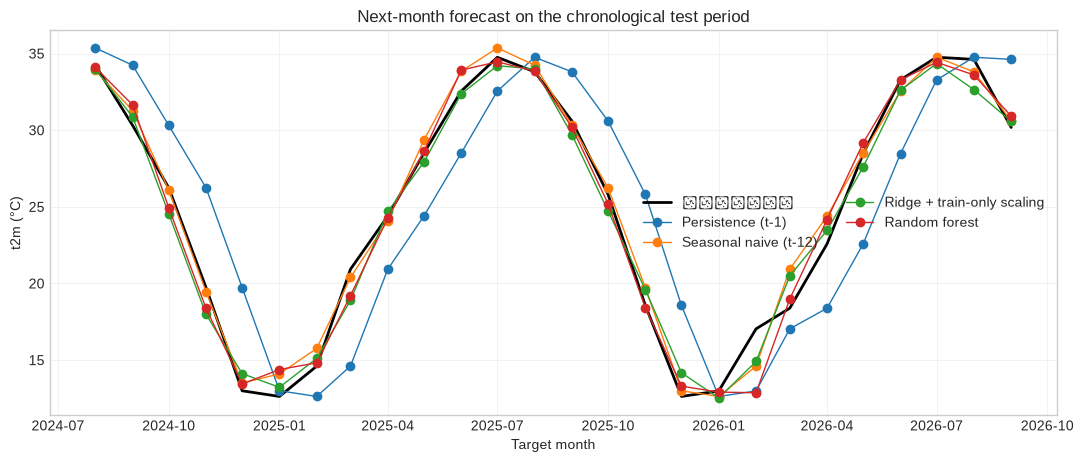

In [ ]:
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(y_test.index, y_test, color="black", linewidth=2, label="Vérité")
for name, pred in predictions.items():
    ax.plot(y_test.index, pred, marker="o", linewidth=1, label=name)
ax.set(title="Prévision du mois suivant sur la période de test chronologique", xlabel="Mois cible", ylabel="t2m (°C)")
ax.legend(ncol=2); ax.grid(alpha=.25); plt.show()

### Limites d'inférence
Cet exemple prédit la moyenne régionale, et non de nouveaux sites. L'évaluation temporelle est appropriée pour une question de prévision future, mais ne teste pas la généralisation du modèle à une zone spatiale invisible. Pour la prévision spatiale, des blocs géographiques adjacents complets sont réservés. L'erreur doit être comparée aux lignes de base, et la performance d'une courte période ne doit pas être interprétée comme une capacité à long terme.